# Code tutorial connectomics I - Computational Neuroscience

This tutorial recreates the Rich Club analysis from Towlson et al., 2013, Journal of Neuroscience

# Imports and installation

In [8]:
#!git clone https://github.com/ChristianPritz/unito_connectomics_i
#%cd unito_connectomics_i
import os
import sys
import pandas as pd
import networkx as nx
from networkx.algorithms import community
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
sys.path.append(os.getcwd()+'/code')
from connectomics_functions import *

## Here we're gonna explore some basic concepts about graphs in connectomics: 
* Let's load an adjacency matrix and see what the graph looks like and 
* the let's examine some basic statistics. 


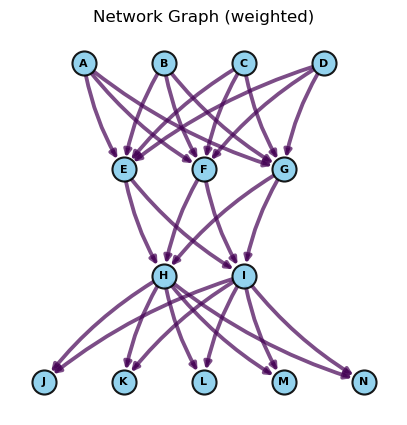

/home/wormulon/models/unito_computational_neuroscience/connectomics_i/code/connectomics_functions.py:218: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


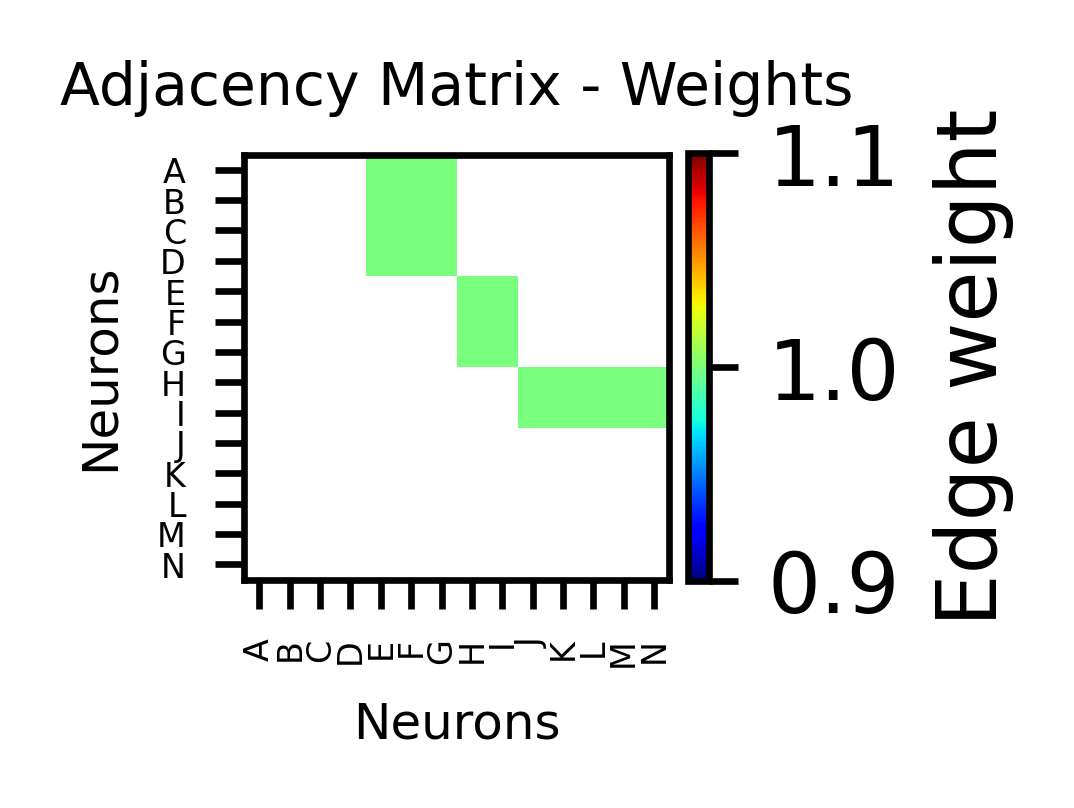

Total number of connections: 28
Average in-degree: 2.0
Average out-degree: 2.0
------------------------------------------------------------------
Average min. path length: 1.8873239436619718
Reachability 39.01098901098901 %


In [2]:
# loading the adjacency matrix from a csv file in the data folder
A_machine, nodes = load_adjacency_matrix(os.getcwd()+"/data/testConn.csv")
#instantiating the the graph and renaming the neurons 
G_machine = nx.from_numpy_array(A_machine, create_using=nx.DiGraph)
G_machine = nx.relabel_nodes(G_machine, dict(enumerate(nodes)))

# this variable sorts the position of the neurons in the graph
positions = {"A": [0,0],
             "B": [1,0],
             "C": [2,0],
             "D": [3,0],
             "E": [0.5,-1],
             "F": [1.5,-1],
             "G": [2.5,-1],
             "H": [1,-2],
             "I": [2,-2],
             "J": [-0.5,-3],
             "K": [0.5,-3],
             "L": [1.5,-3],
             "M": [2.5,-3],
             "N": [3.5,-3],}

#Let us plot the graph 
plot_network(G_machine,positions=positions)
plot_adjacency_matrix(G_machine,sort_nodes=False, figsize=(1,1))
basic_stats(G_machine)





### This doesn't look like a graph from biological network. 
Let's rework the graph  so that the information can flow bi-directionally. Try to edit it until the reachability is 100% and graph is fully connected. 

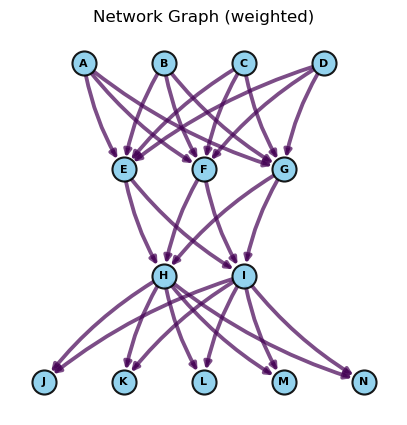

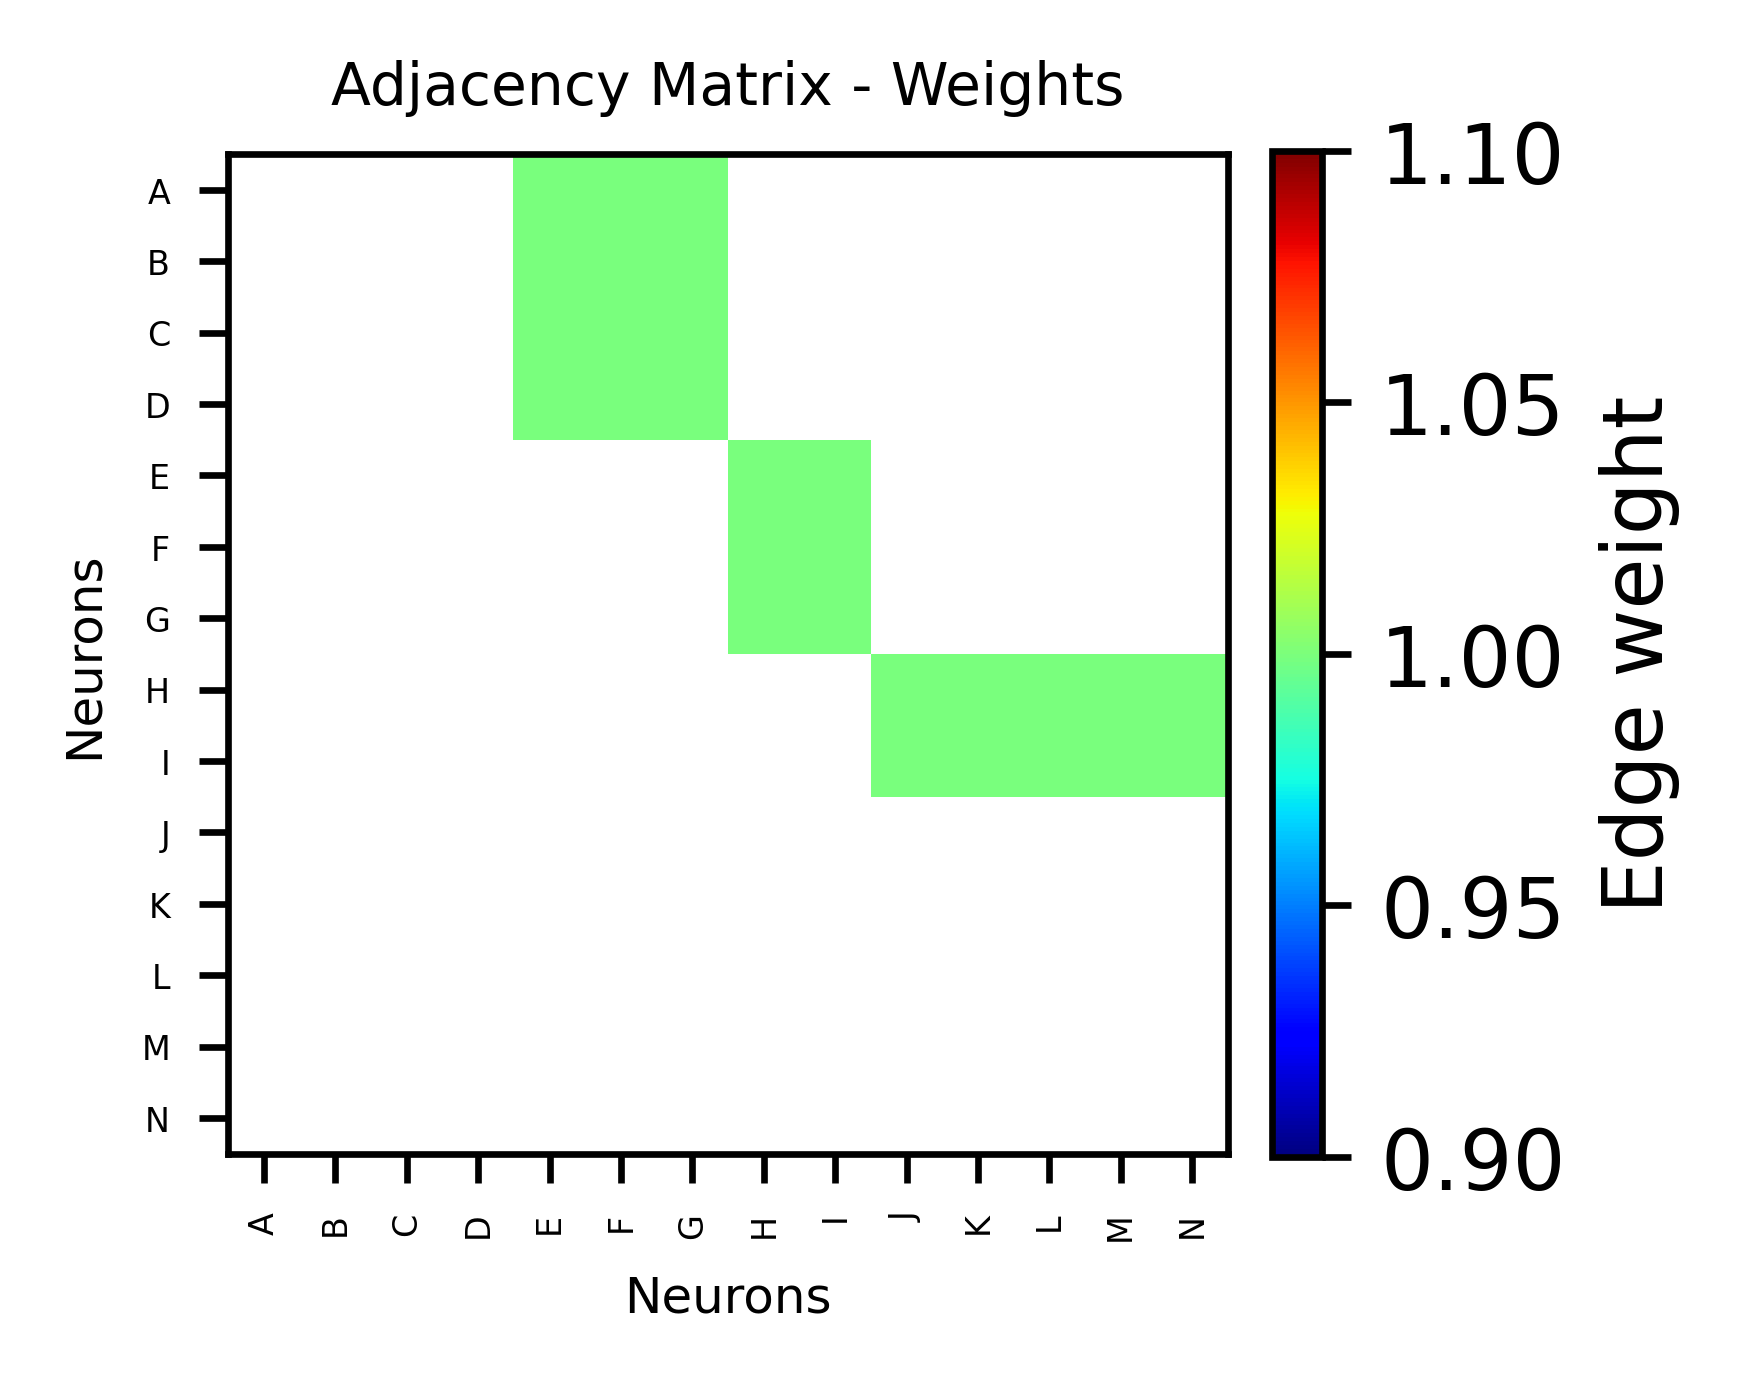

Total number of connections: 28
Average in-degree: 2.0
Average out-degree: 2.0
------------------------------------------------------------------
Average min. path length: 1.8873239436619718
Reachability 39.01098901098901 %


In [9]:

A_edit = np.array([[0., 0., 0., 0., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0.],
                   [0., 0., 0., 0., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0.],
                   [0., 0., 0., 0., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0.],
                   [0., 0., 0., 0., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0.],
                   [0., 0., 0., 0., 0., 0., 0., 1., 1., 0., 0., 0., 0., 0.],
                   [0., 0., 0., 0., 0., 0., 0., 1., 1., 0., 0., 0., 0., 0.],
                   [0., 0., 0., 0., 0., 0., 0., 1., 1., 0., 0., 0., 0., 0.],
                   [0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 1., 1.],
                   [0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 1., 1.],
                   [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
                   [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
                   [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
                   [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
                   [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])


G_edit = nx.from_numpy_array(A_edit, create_using=nx.DiGraph)
G_edit = nx.relabel_nodes(G_edit, dict(enumerate(nodes)))
plot_network(G_edit,positions=positions)
plot_adjacency_matrix(G_edit,sort_nodes=False, figsize=(3,3))
basic_stats(G_edit)

# Teacher cell

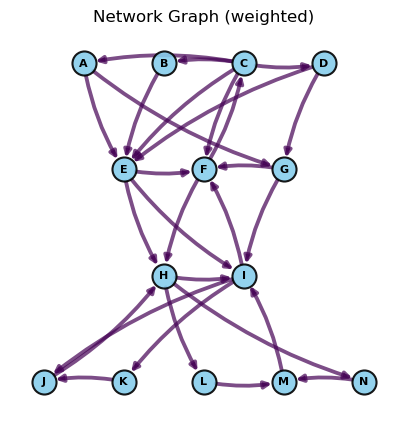

/home/wormulon/models/unito_computational_neuroscience/connectomics_i/code/connectomics_functions.py:218: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


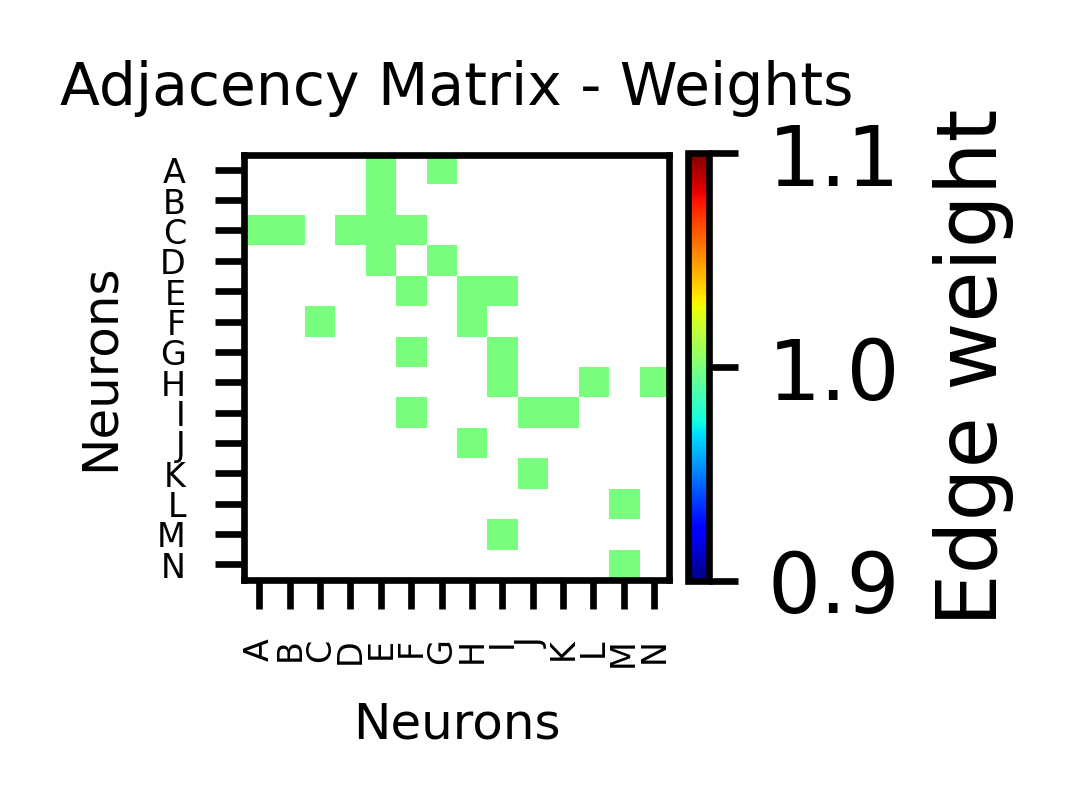

Total number of connections: 28
Average in-degree: 2.0
Average out-degree: 2.0
------------------------------------------------------------------
Average min. path length: 2.9615384615384617
Reachability 100.0 %


In [10]:
# loading the adjacency matrix from a csv file in the data folder
A_bio, nodes = load_adjacency_matrix(os.getcwd()+"/data/testConn2.csv")
#instantiating the the graph and renaming the neurons 
G_bio = nx.from_numpy_array(A_bio, create_using=nx.DiGraph)
G_bio = nx.relabel_nodes(G_bio, dict(enumerate(nodes)))

#Let us plot the graph 
plot_network(G_bio,positions=positions)
plot_adjacency_matrix(G_bio,sort_nodes=False, figsize=(1,1))
basic_stats(G_bio)

# Let's load the C.elegans connectome

In [11]:
# ======== LOAD DATA ==========================================================
edge_list_path = "./data/NeuronConnect.csv"
raw_data = pd.read_csv(edge_list_path)
raw_data = raw_data.rename(columns={'Nbr': 'weight'})

raw_data = raw_data.drop(np.where(raw_data.Type == "NMJ")[0])

# instantiating a directed graph
G_dir = nx.from_pandas_edgelist(
    raw_data,
    source='Neuron 1',
    target='Neuron 2',
    edge_attr='weight',
    create_using=nx.DiGraph()
)

#the edges are stored in adjacency dict
print('#############################################################')
print("The adjacency matrix has", str(len(G_dir._adj)), "entries")
print("Individual edges per neurons in this dict look like the \n this (AWCR as example):")
for nbr, datadict in G_dir.adj['AWCR'].items():
    print(nbr,datadict)


#nodes are stored in a the nodes property. 
print('#############################################################')
nodes = list(G_dir.nodes)[:10]
print("Nodes are stored in the 'node' property")
print(f"{nodes} ... and many more")

#############################################################
The adjacency matrix has 281 entries
Individual edges per neurons in this dict look like the 
 this (AWCR as example):
ADLR {'weight': 3}
AIAL {'weight': 1}
AIAR {'weight': 1}
AIBR {'weight': 4}
AIYL {'weight': 3}
AIYR {'weight': 6}
ASEL {'weight': 1}
ASER {'weight': 1}
ASGR {'weight': 1}
ASIL {'weight': 1}
ASIR {'weight': 1}
AWCL {'weight': 4}
#############################################################
Nodes are stored in the 'node' property
['ADAR', 'ADAL', 'ADFL', 'ASHL', 'AVDR', 'PVQL', 'ADEL', 'AIAL', 'AIBL', 'AIBR'] ... and many more


### Let us see the adjacency matrix
#### Note that the adjacency matrix is sparse! 

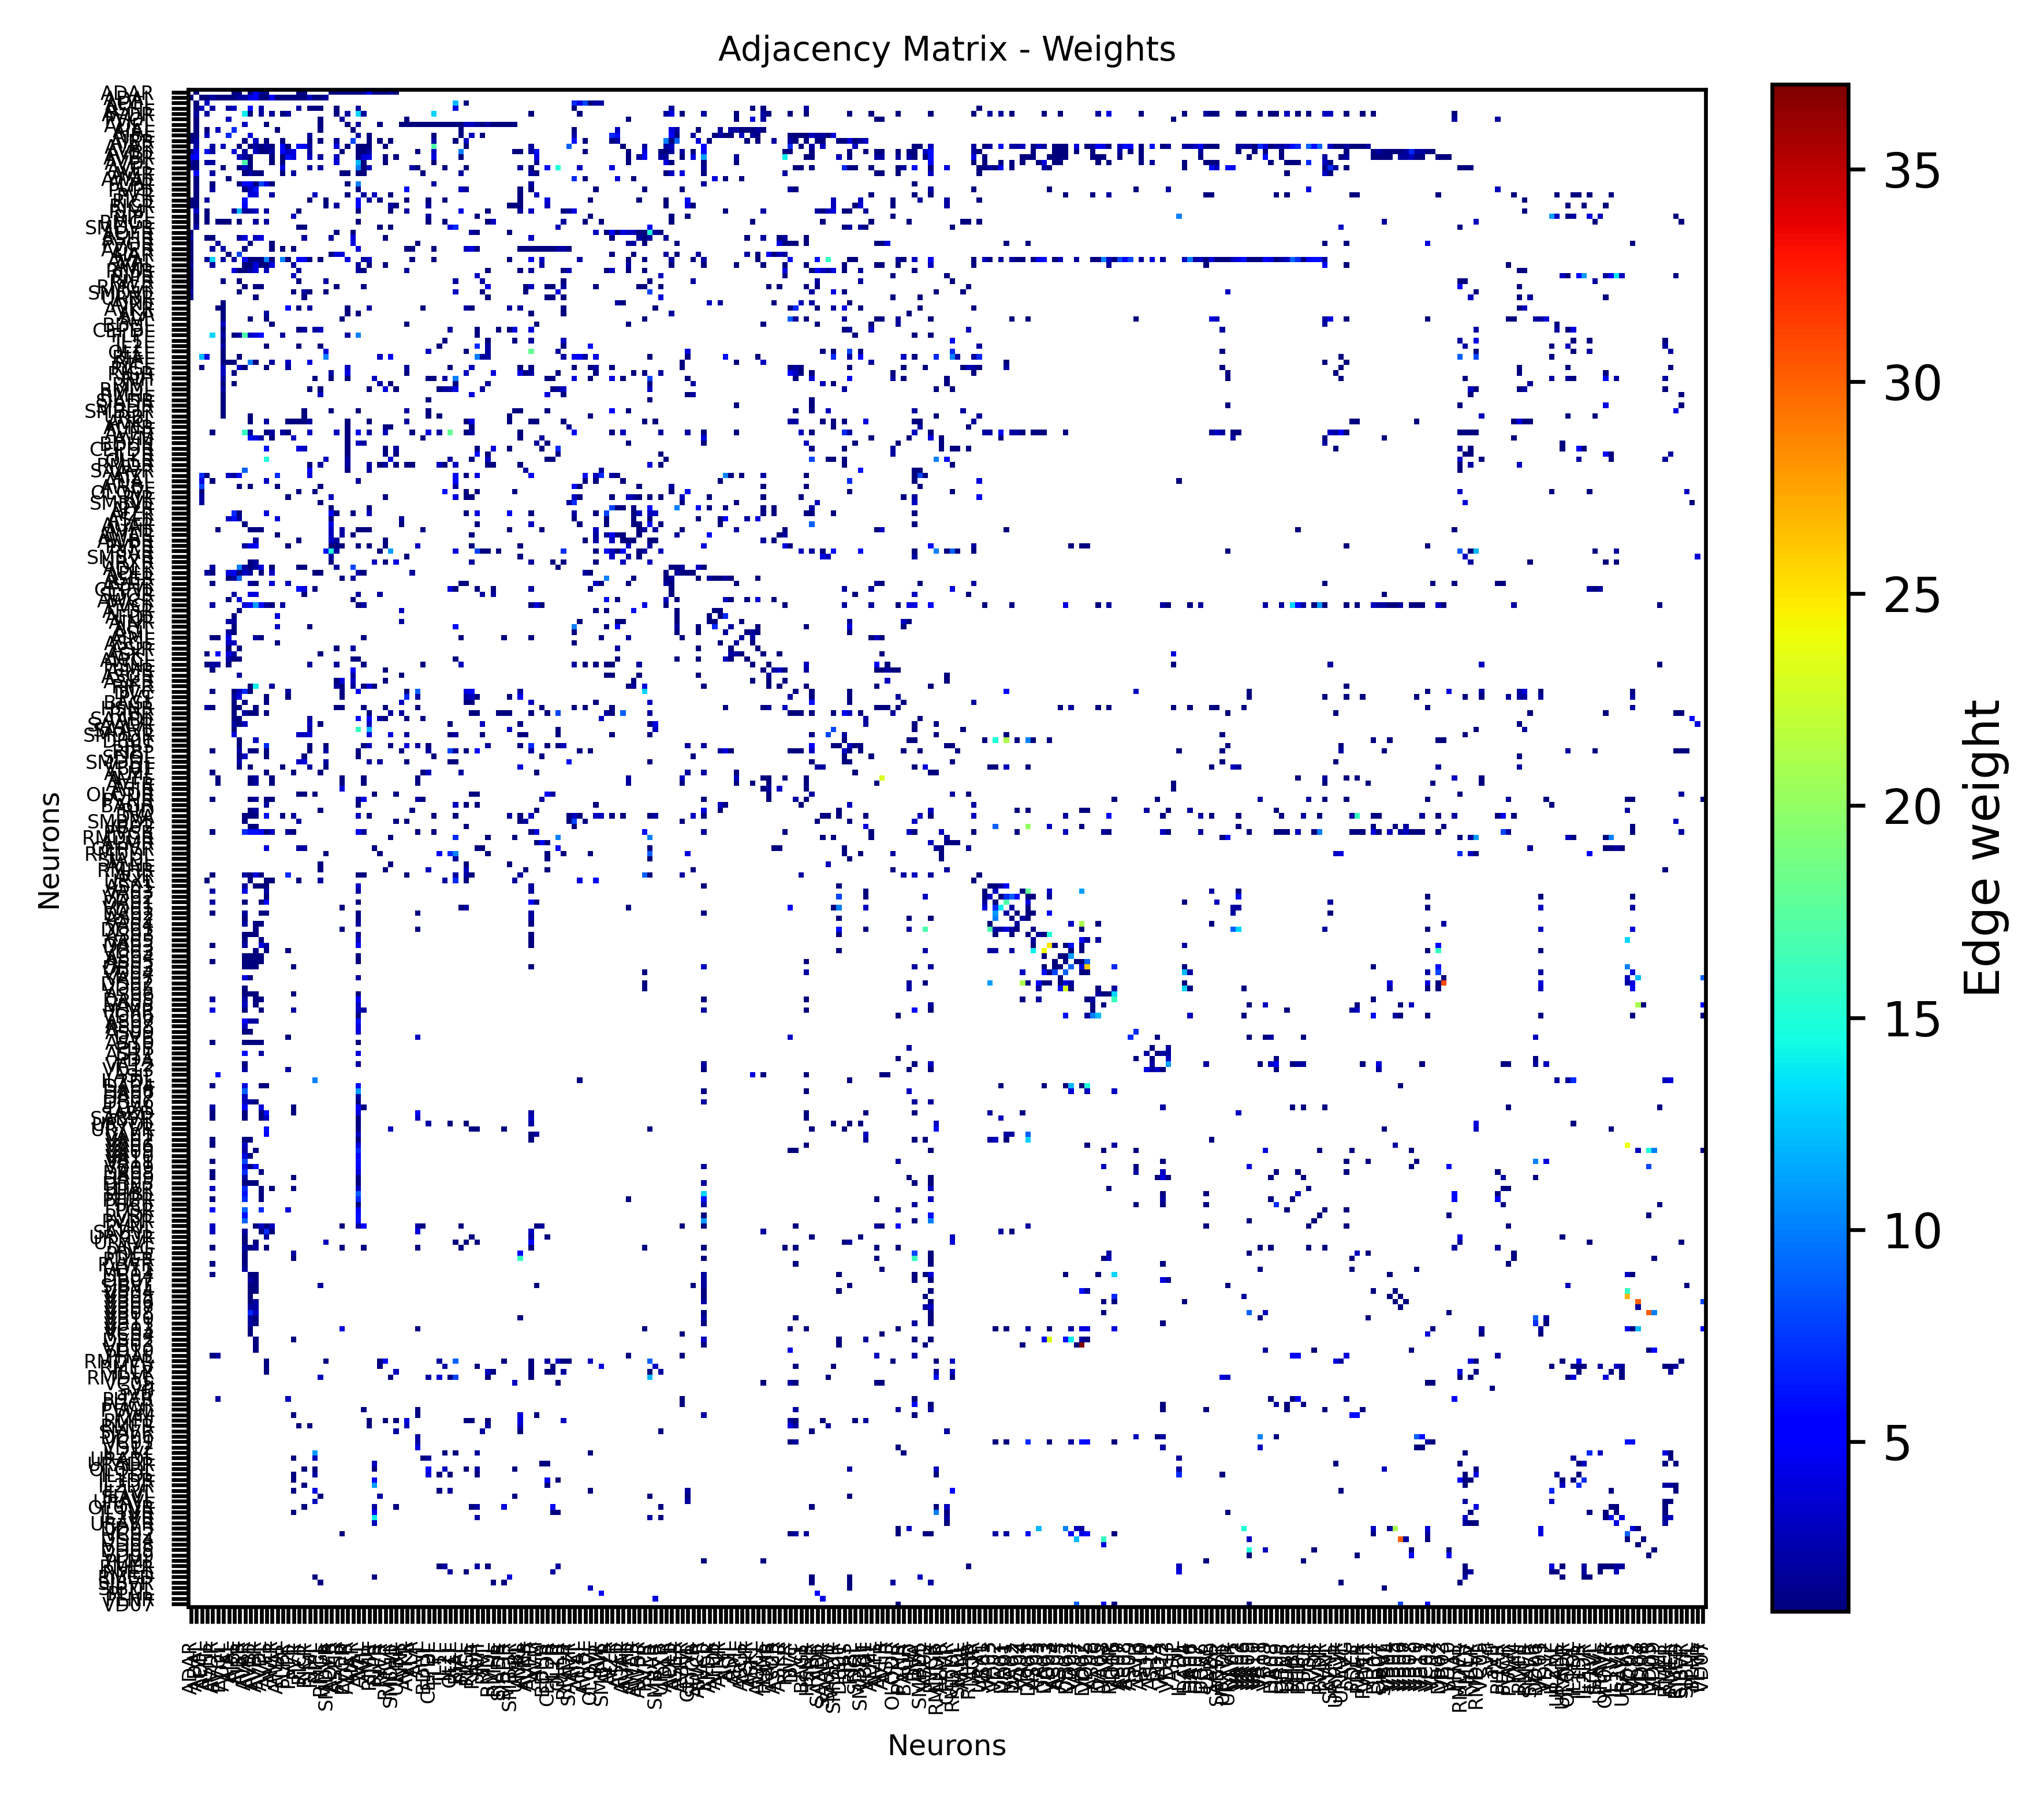

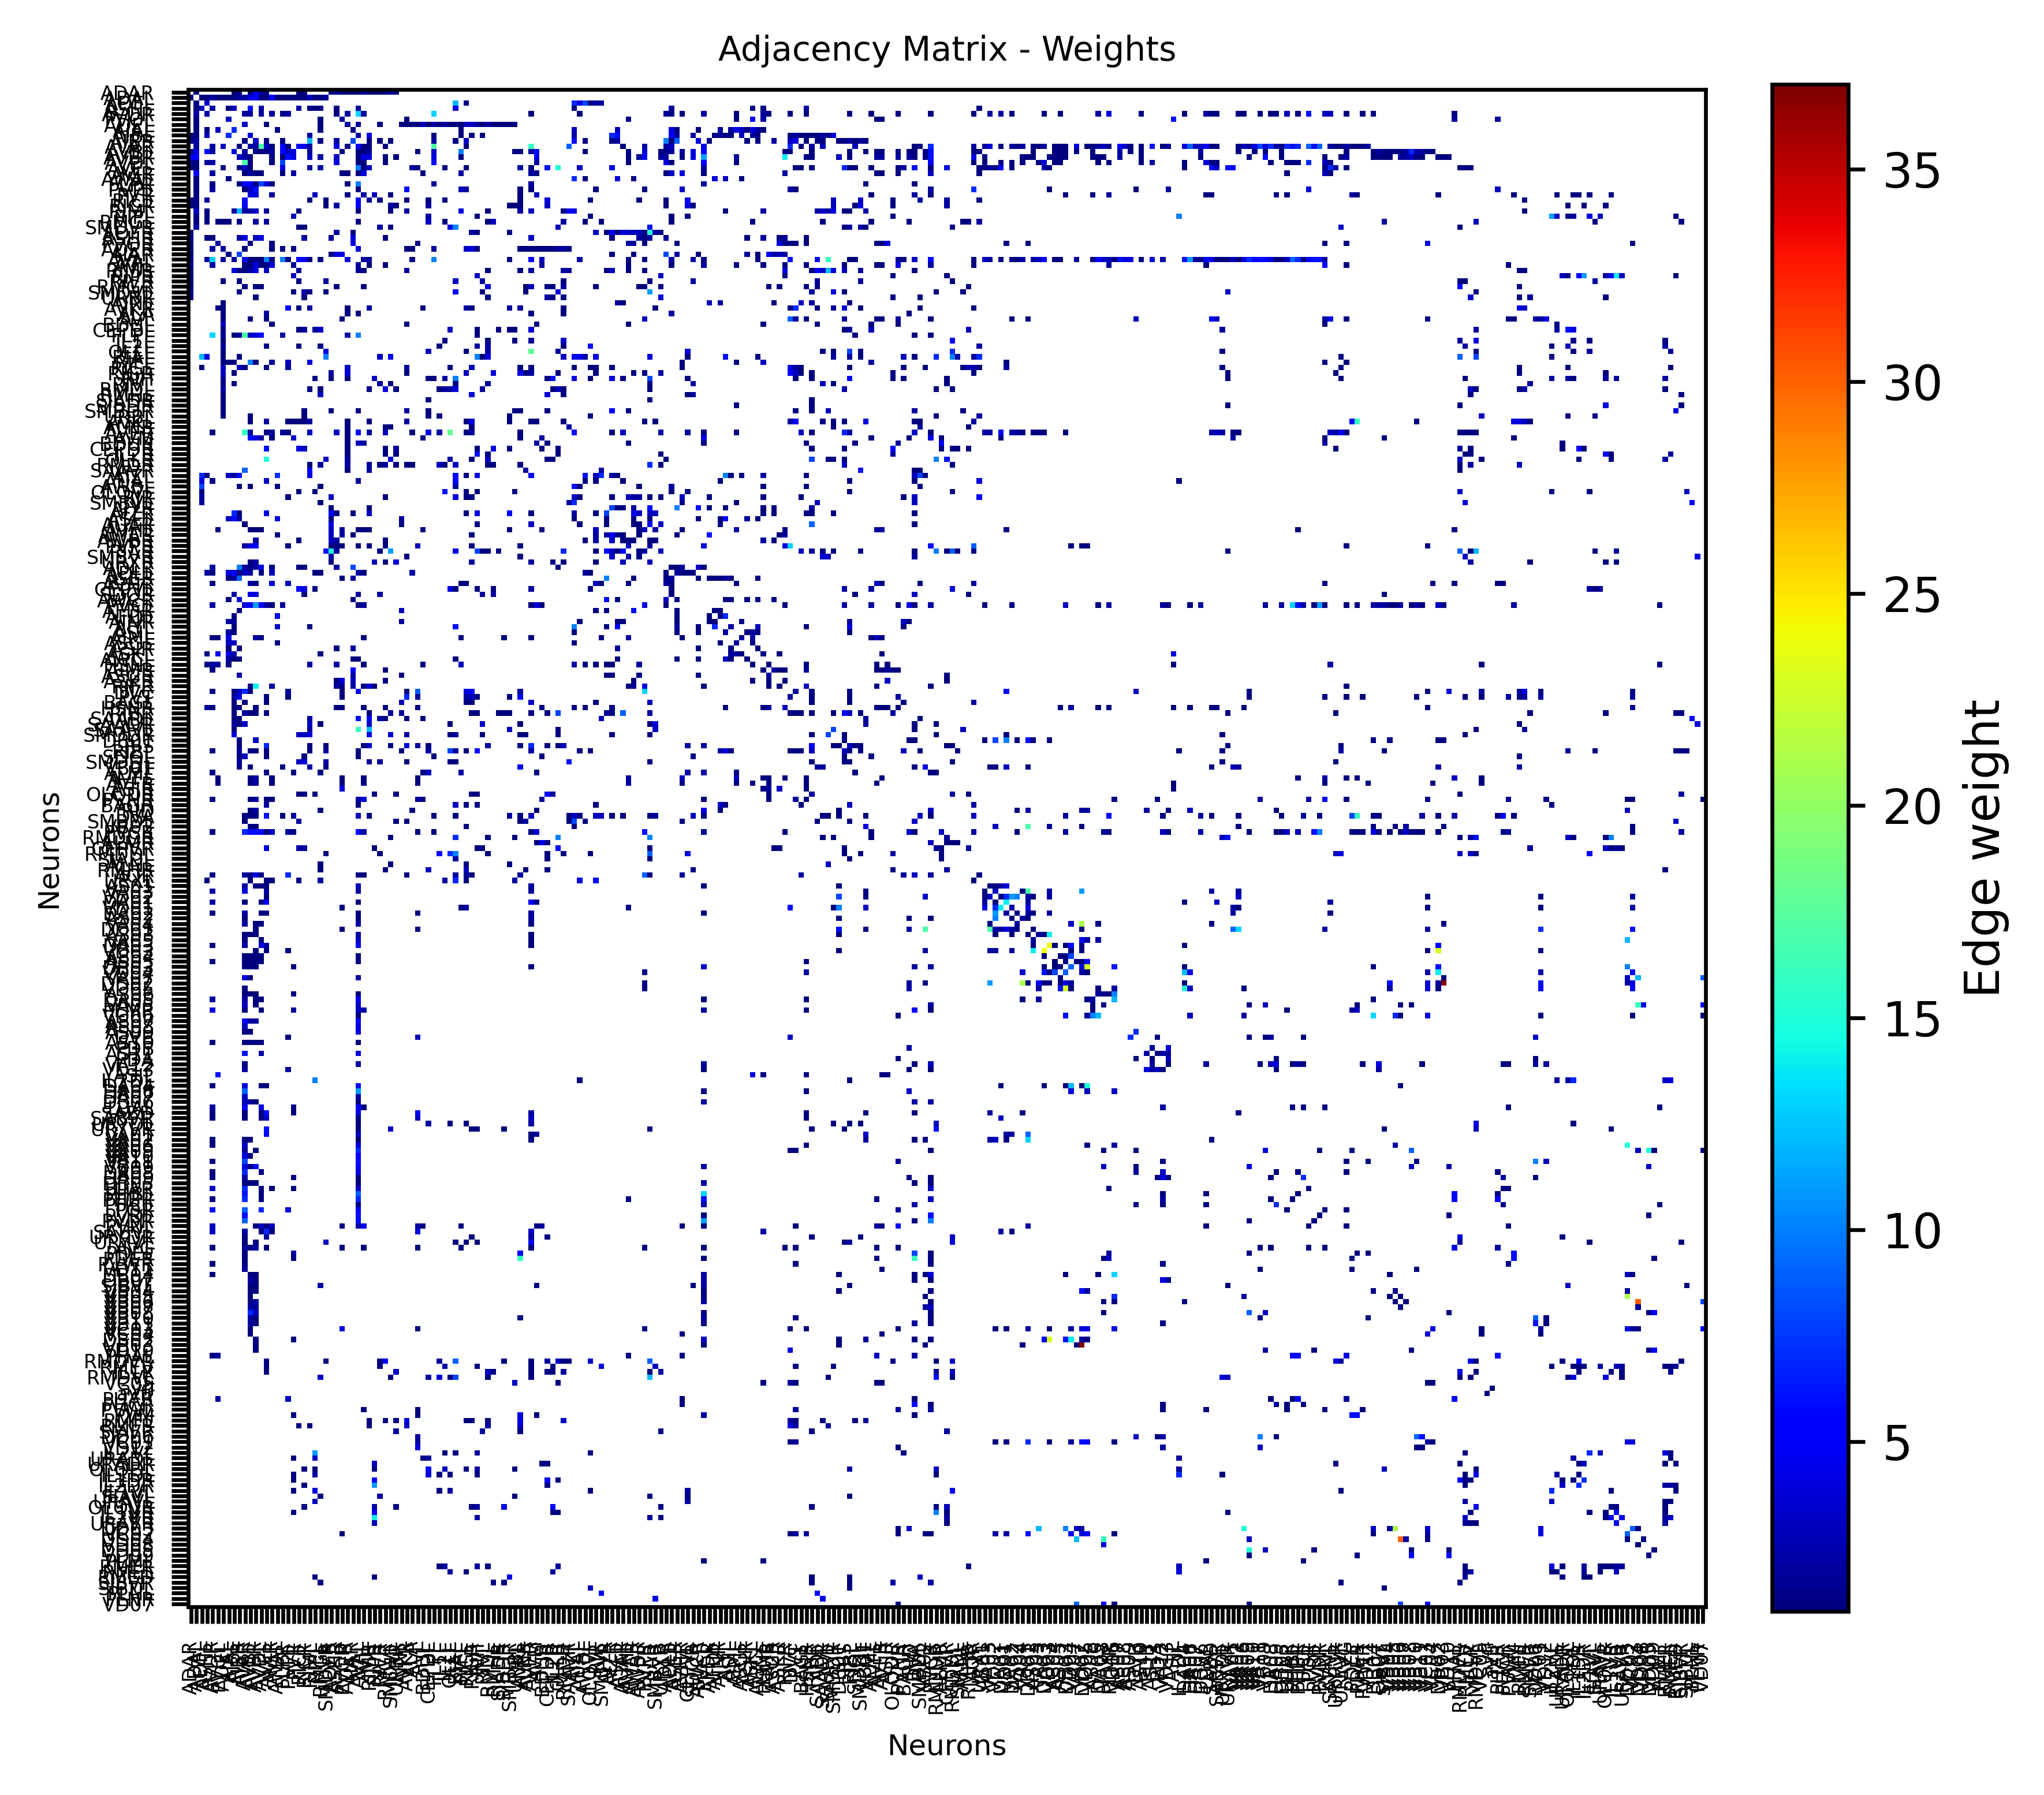

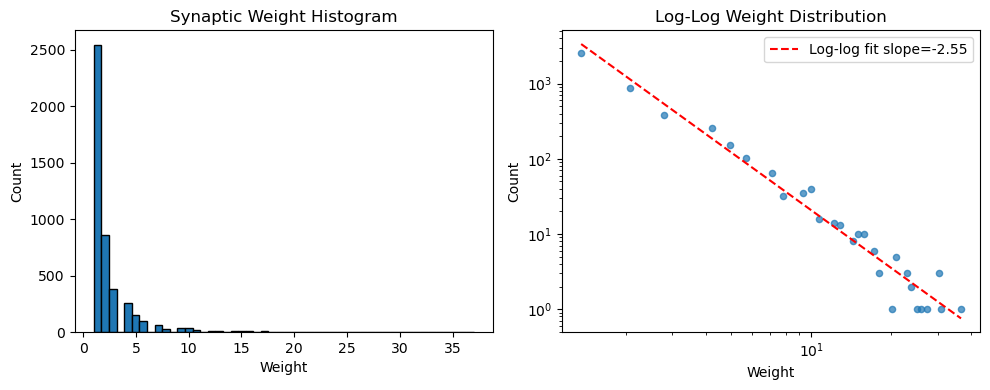

In [26]:
#plotting a adjacency matrix 
plot_adjacency_matrix(G_dir,cmap='jet',sort_nodes=False,figsize=(6,6))

#the undirected graph would look like this: 
G_und = G_dir.to_undirected()
plot_adjacency_matrix(G_und,cmap='jet',sort_nodes=False,figsize=(6,6))

plot_weight_distribution(G_dir, bins=50, fit_powerlaw=True)




# Let's compute the rich club

* we determine if a rich club candidate neuron is signficiant if: rc[real] > rc[rand] + stdev(rc[rand])
   

Rich-club threshold degree: 41
Number of neurons in rich club: 11
Rich-club neurons: ['AVDR', 'AVAR', 'AVBL', 'AVBR', 'AVDL', 'AVEL', 'AVAL', 'AVER', 'PVCL', 'DVA', 'PVCR']


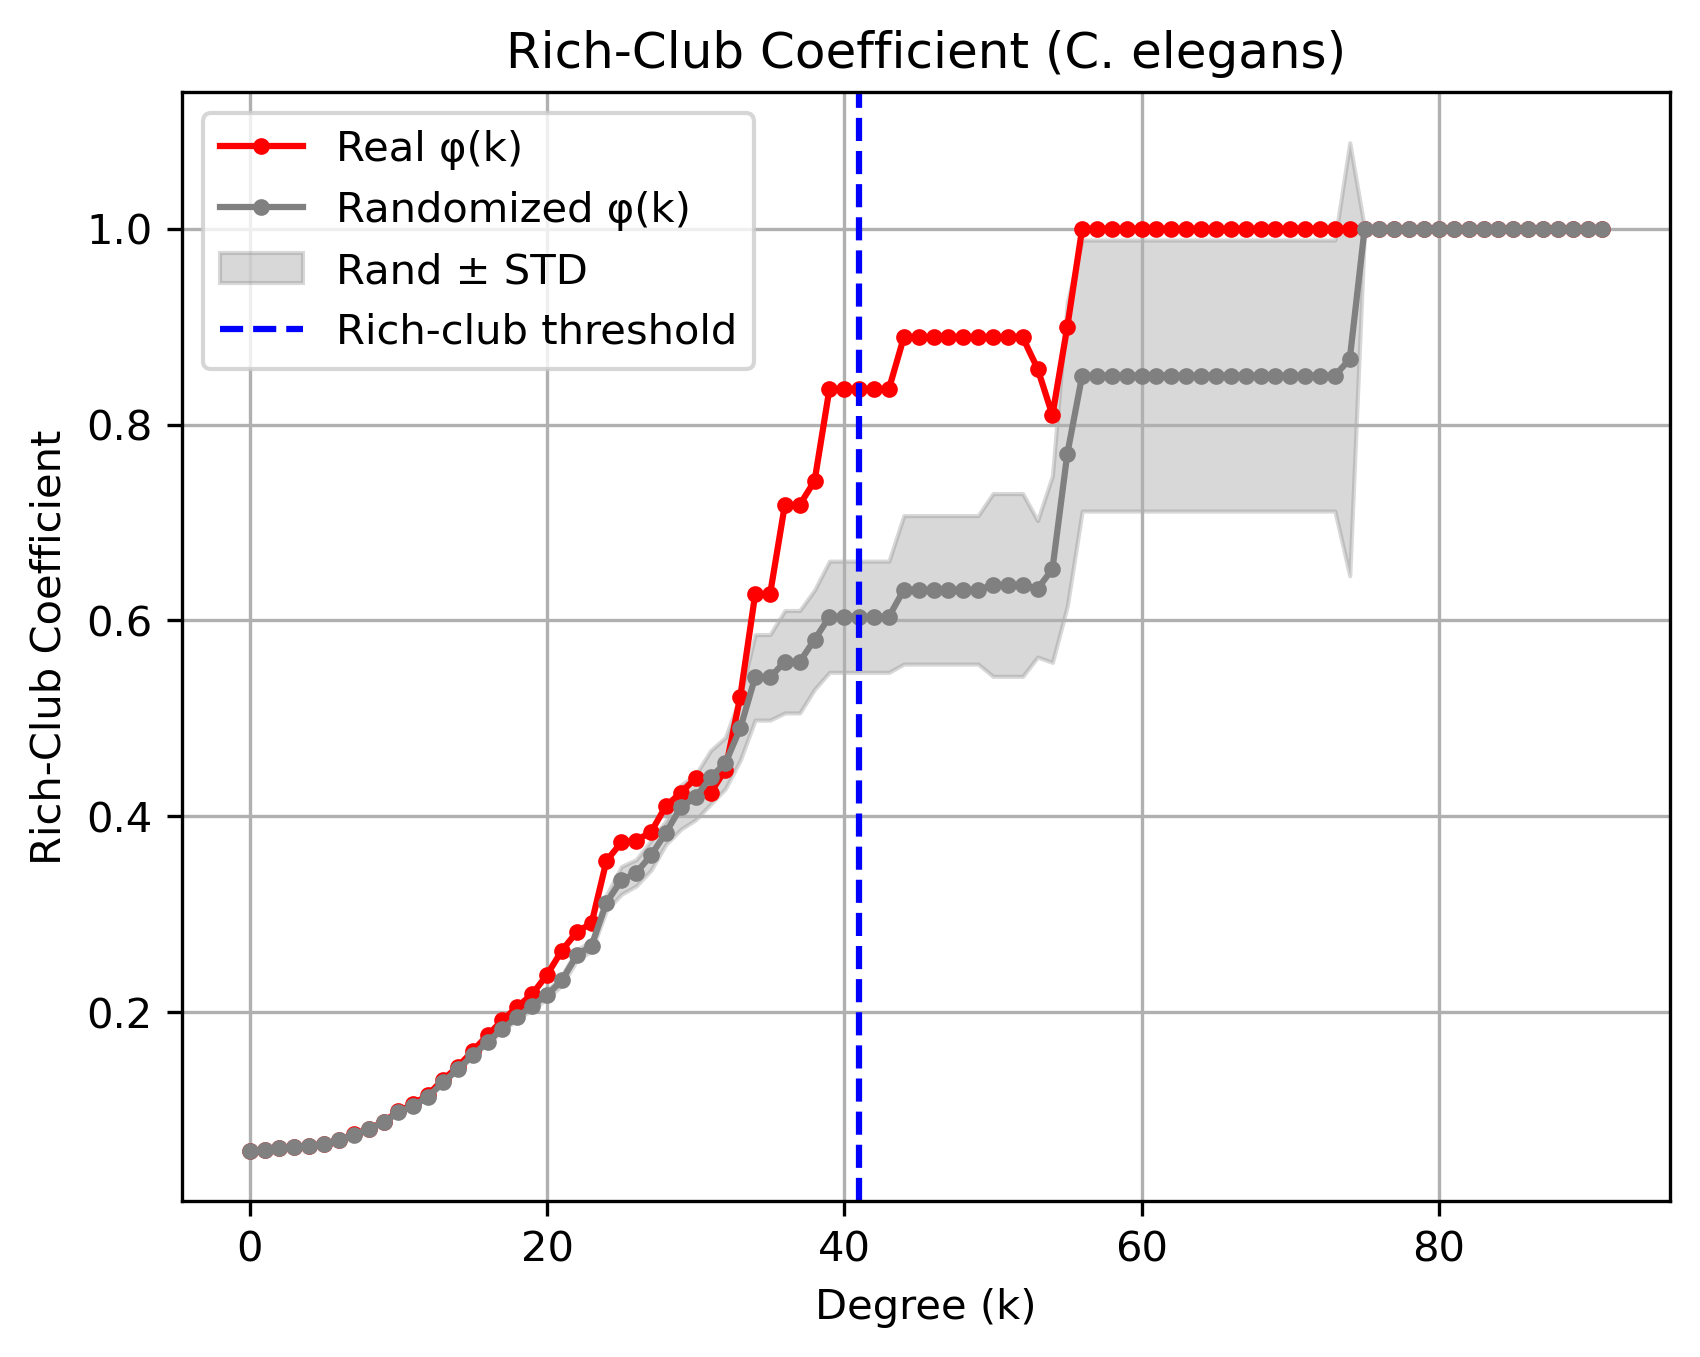

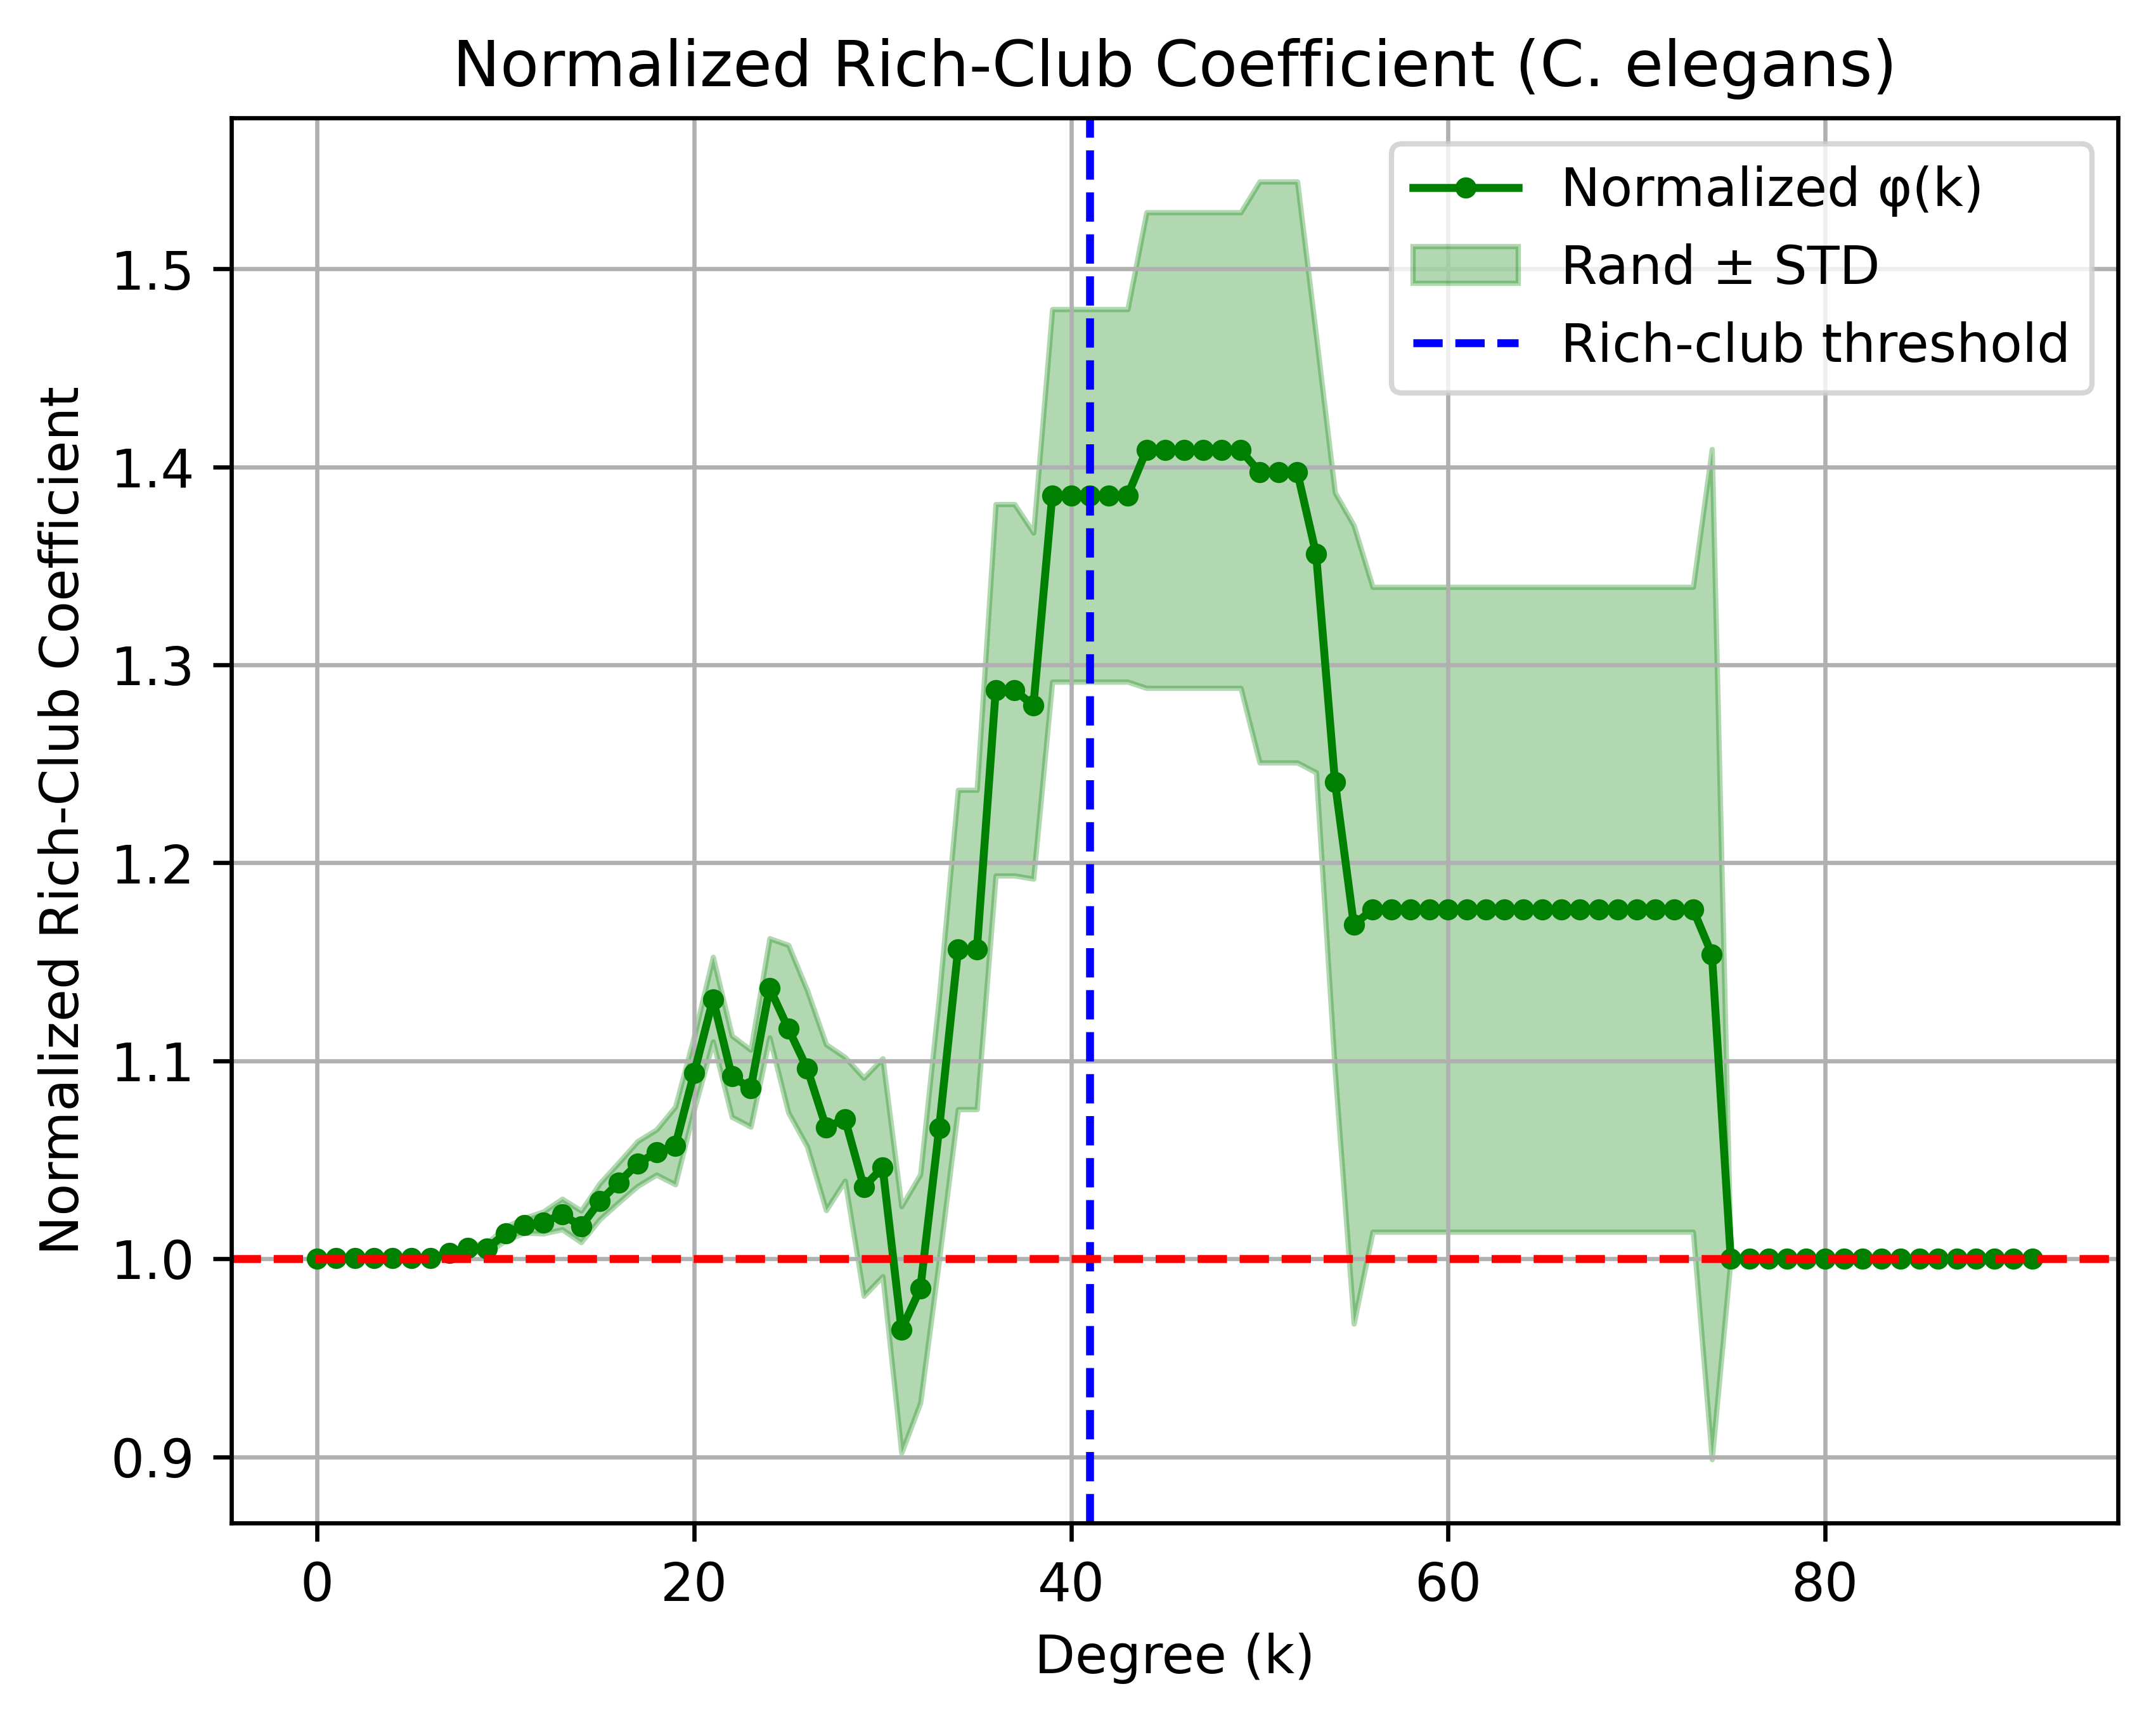

In [12]:
# ======== COMPUTE RICH-CLUB ========
rc_real, rc_rand_avg, rc_rand_std, rc_norm =  rich_club(G_dir, method="config_preserving",n_rand=10)

# Convert to undirected and get degrees
G_und = G_dir.to_undirected()
degrees = dict(G_und.degree())


# ======== DETERMINE RICH-CLUB THRESHOLD ========
k_vals = list(rc_real.keys())
significant_k = [k for k in k_vals if rc_real[k] > rc_rand_avg[k] + rc_rand_std[k]]

if not significant_k:
    print("No significant rich-club degree found")
    k_rich = None
    rich_club_neurons = []
else:
    k_rich = 41 # This is the value from the paper............
    rich_club_neurons = [n for n, d in degrees.items() if d >= k_rich]
    print(f"Rich-club threshold degree: {k_rich}")
    print(f"Number of neurons in rich club: {len(rich_club_neurons)}")
    print("Rich-club neurons:", rich_club_neurons)

plot_rich_club(rc_real,rc_rand_avg,rc_rand_std,rc_norm,k_vals,k_rich)


## Why is the Rich Club at higher degrees not significant?

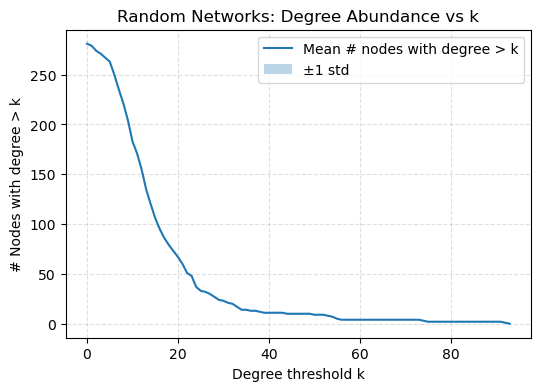

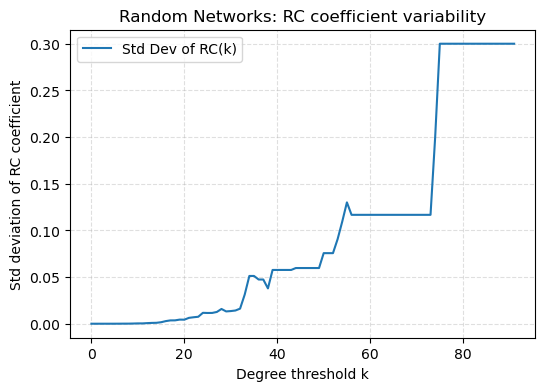

In [13]:
rc_real, rc_rand_avg, rc_rand_std, rc_norm =  rich_club(G_dir, method="config_preserving",n_rand=10,plot_rand_stats=True)

# Teacher cell
visualizing different randomization regimes

################################################
ground truth connectivity:


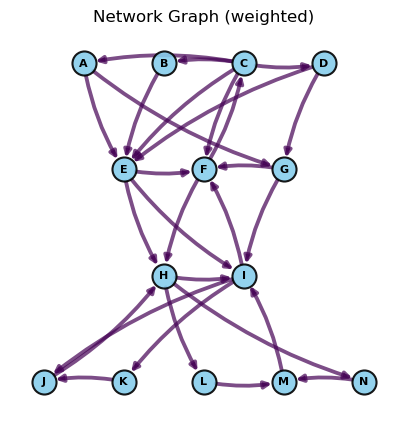

################################################
Randomized, with preserved degrees:


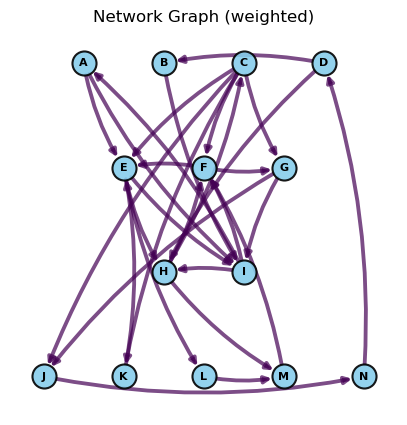

################################################
Erdos Renyi:


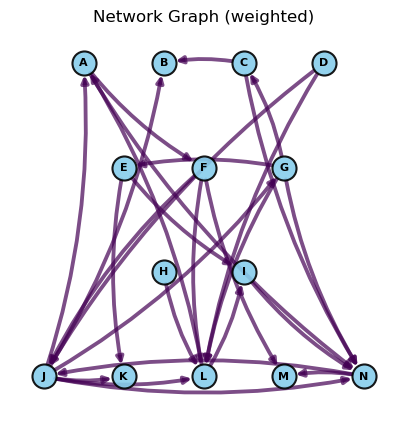

################################################
ground truth connectivity:
Total number of connections: 28
Average in-degree: 2.0
Average out-degree: 2.0
------------------------------------------------------------------
Average min. path length: 2.9615384615384617
Reachability 100.0 %
################################################
Randomized, with preserved degrees:
Total number of connections: 28
Average in-degree: 2.0
Average out-degree: 2.0
------------------------------------------------------------------
Average min. path length: 3.043956043956044
Reachability 100.0 %
################################################
Erdos Renyi:
Total number of connections: 27
Average in-degree: 1.9285714285714286
Average out-degree: 1.9285714285714286
------------------------------------------------------------------
Average min. path length: 2.5365853658536586
Reachability 67.58241758241759 %


In [17]:
g_preserved = randomize_graph(G_bio,method="config_preserving",n_type="directed")
g_erdos = randomize_graph(G_bio,method="erdos_renyi",n_type="directed")

print('################################################')
print("ground truth connectivity:")
plot_network(G_bio,positions=positions)
print('################################################')
print("Randomized, with preserved degrees:")
plot_network(g_preserved,positions=positions)
print('################################################')
print("Erdos Renyi:")
plot_network(g_erdos,positions=positions)

print('################################################')
print("ground truth connectivity:")
basic_stats(G_bio)
print('################################################')
print("Randomized, with preserved degrees:")
basic_stats(g_preserved)
print('################################################')
print("Erdos Renyi:")
basic_stats(g_erdos)


# Let's see how computing the random reference netorks influences the rich club detection. 

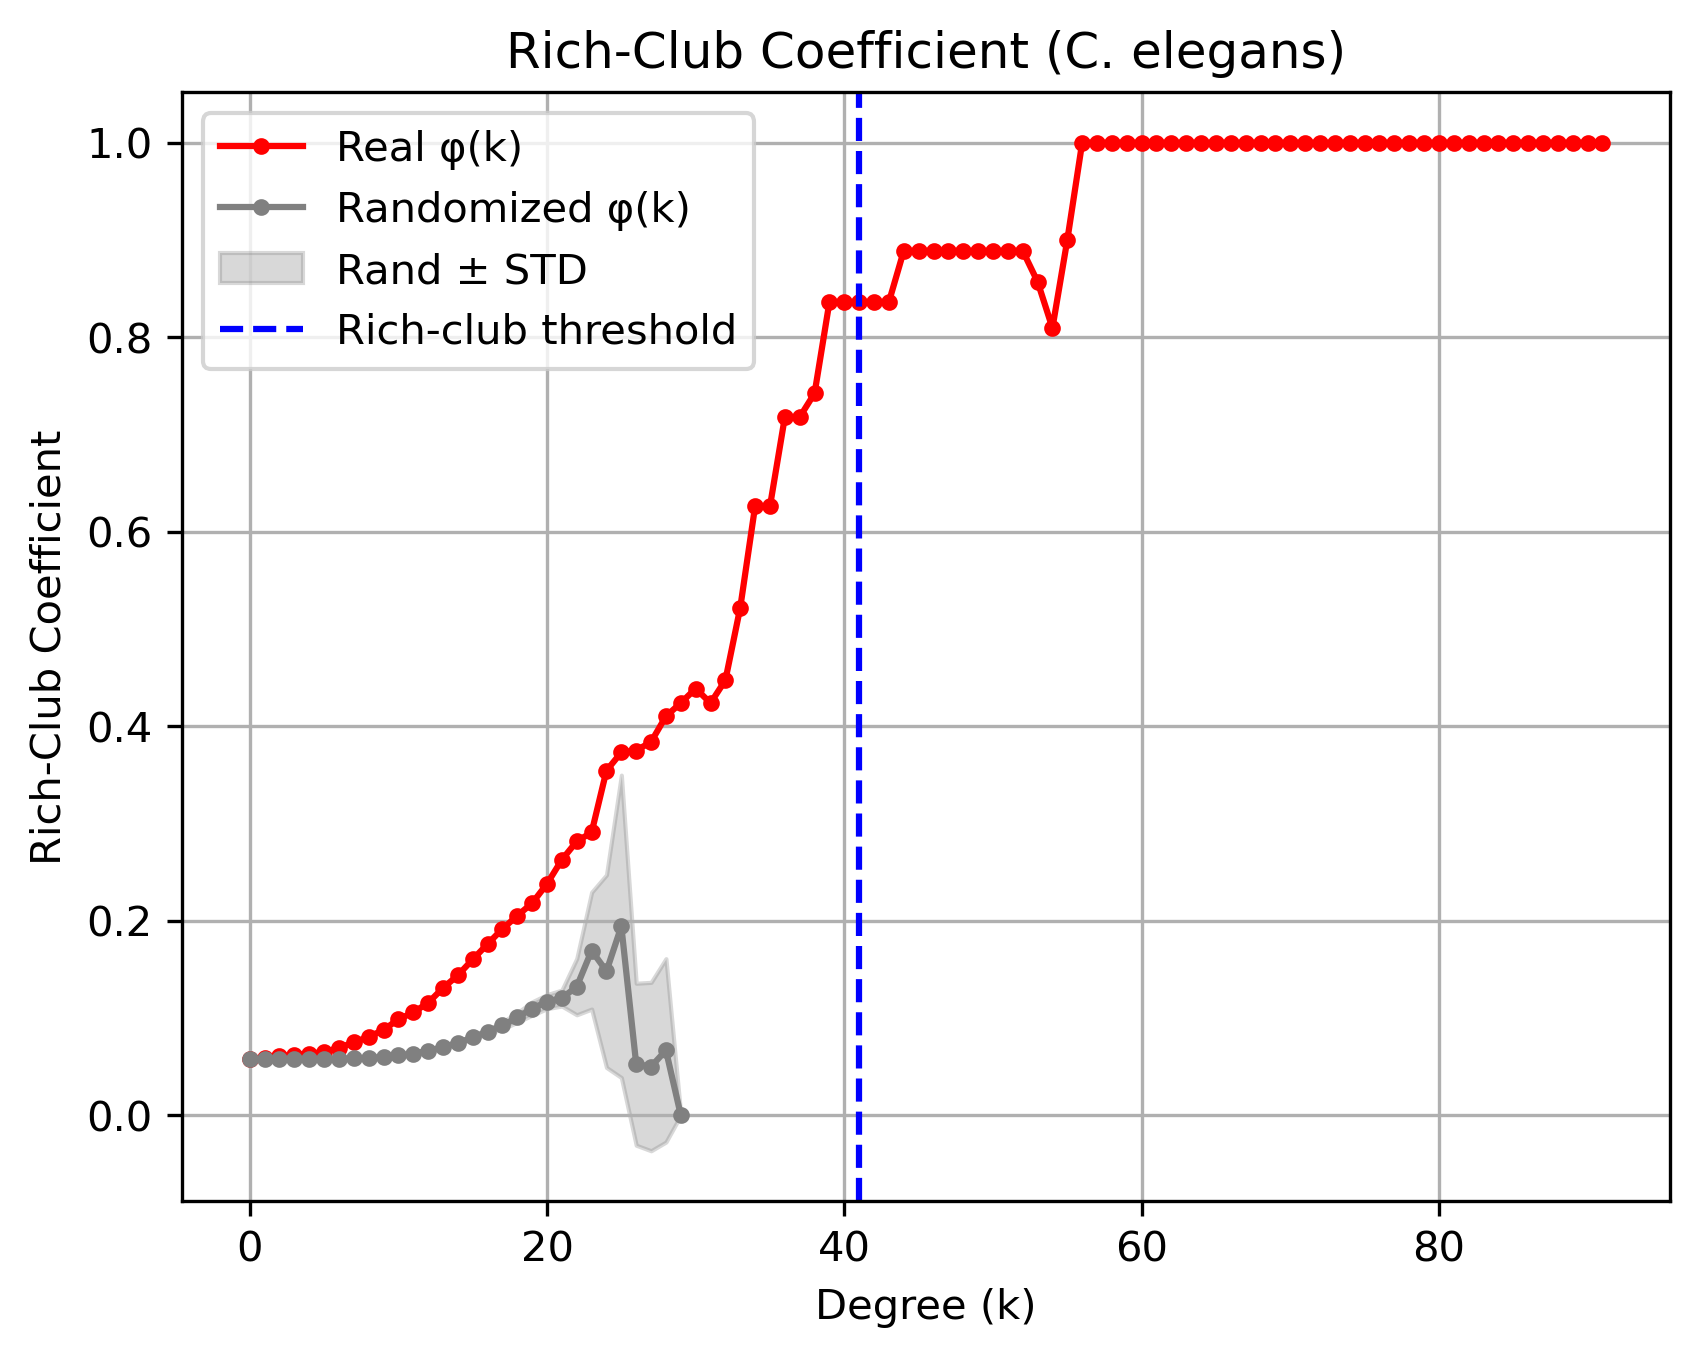

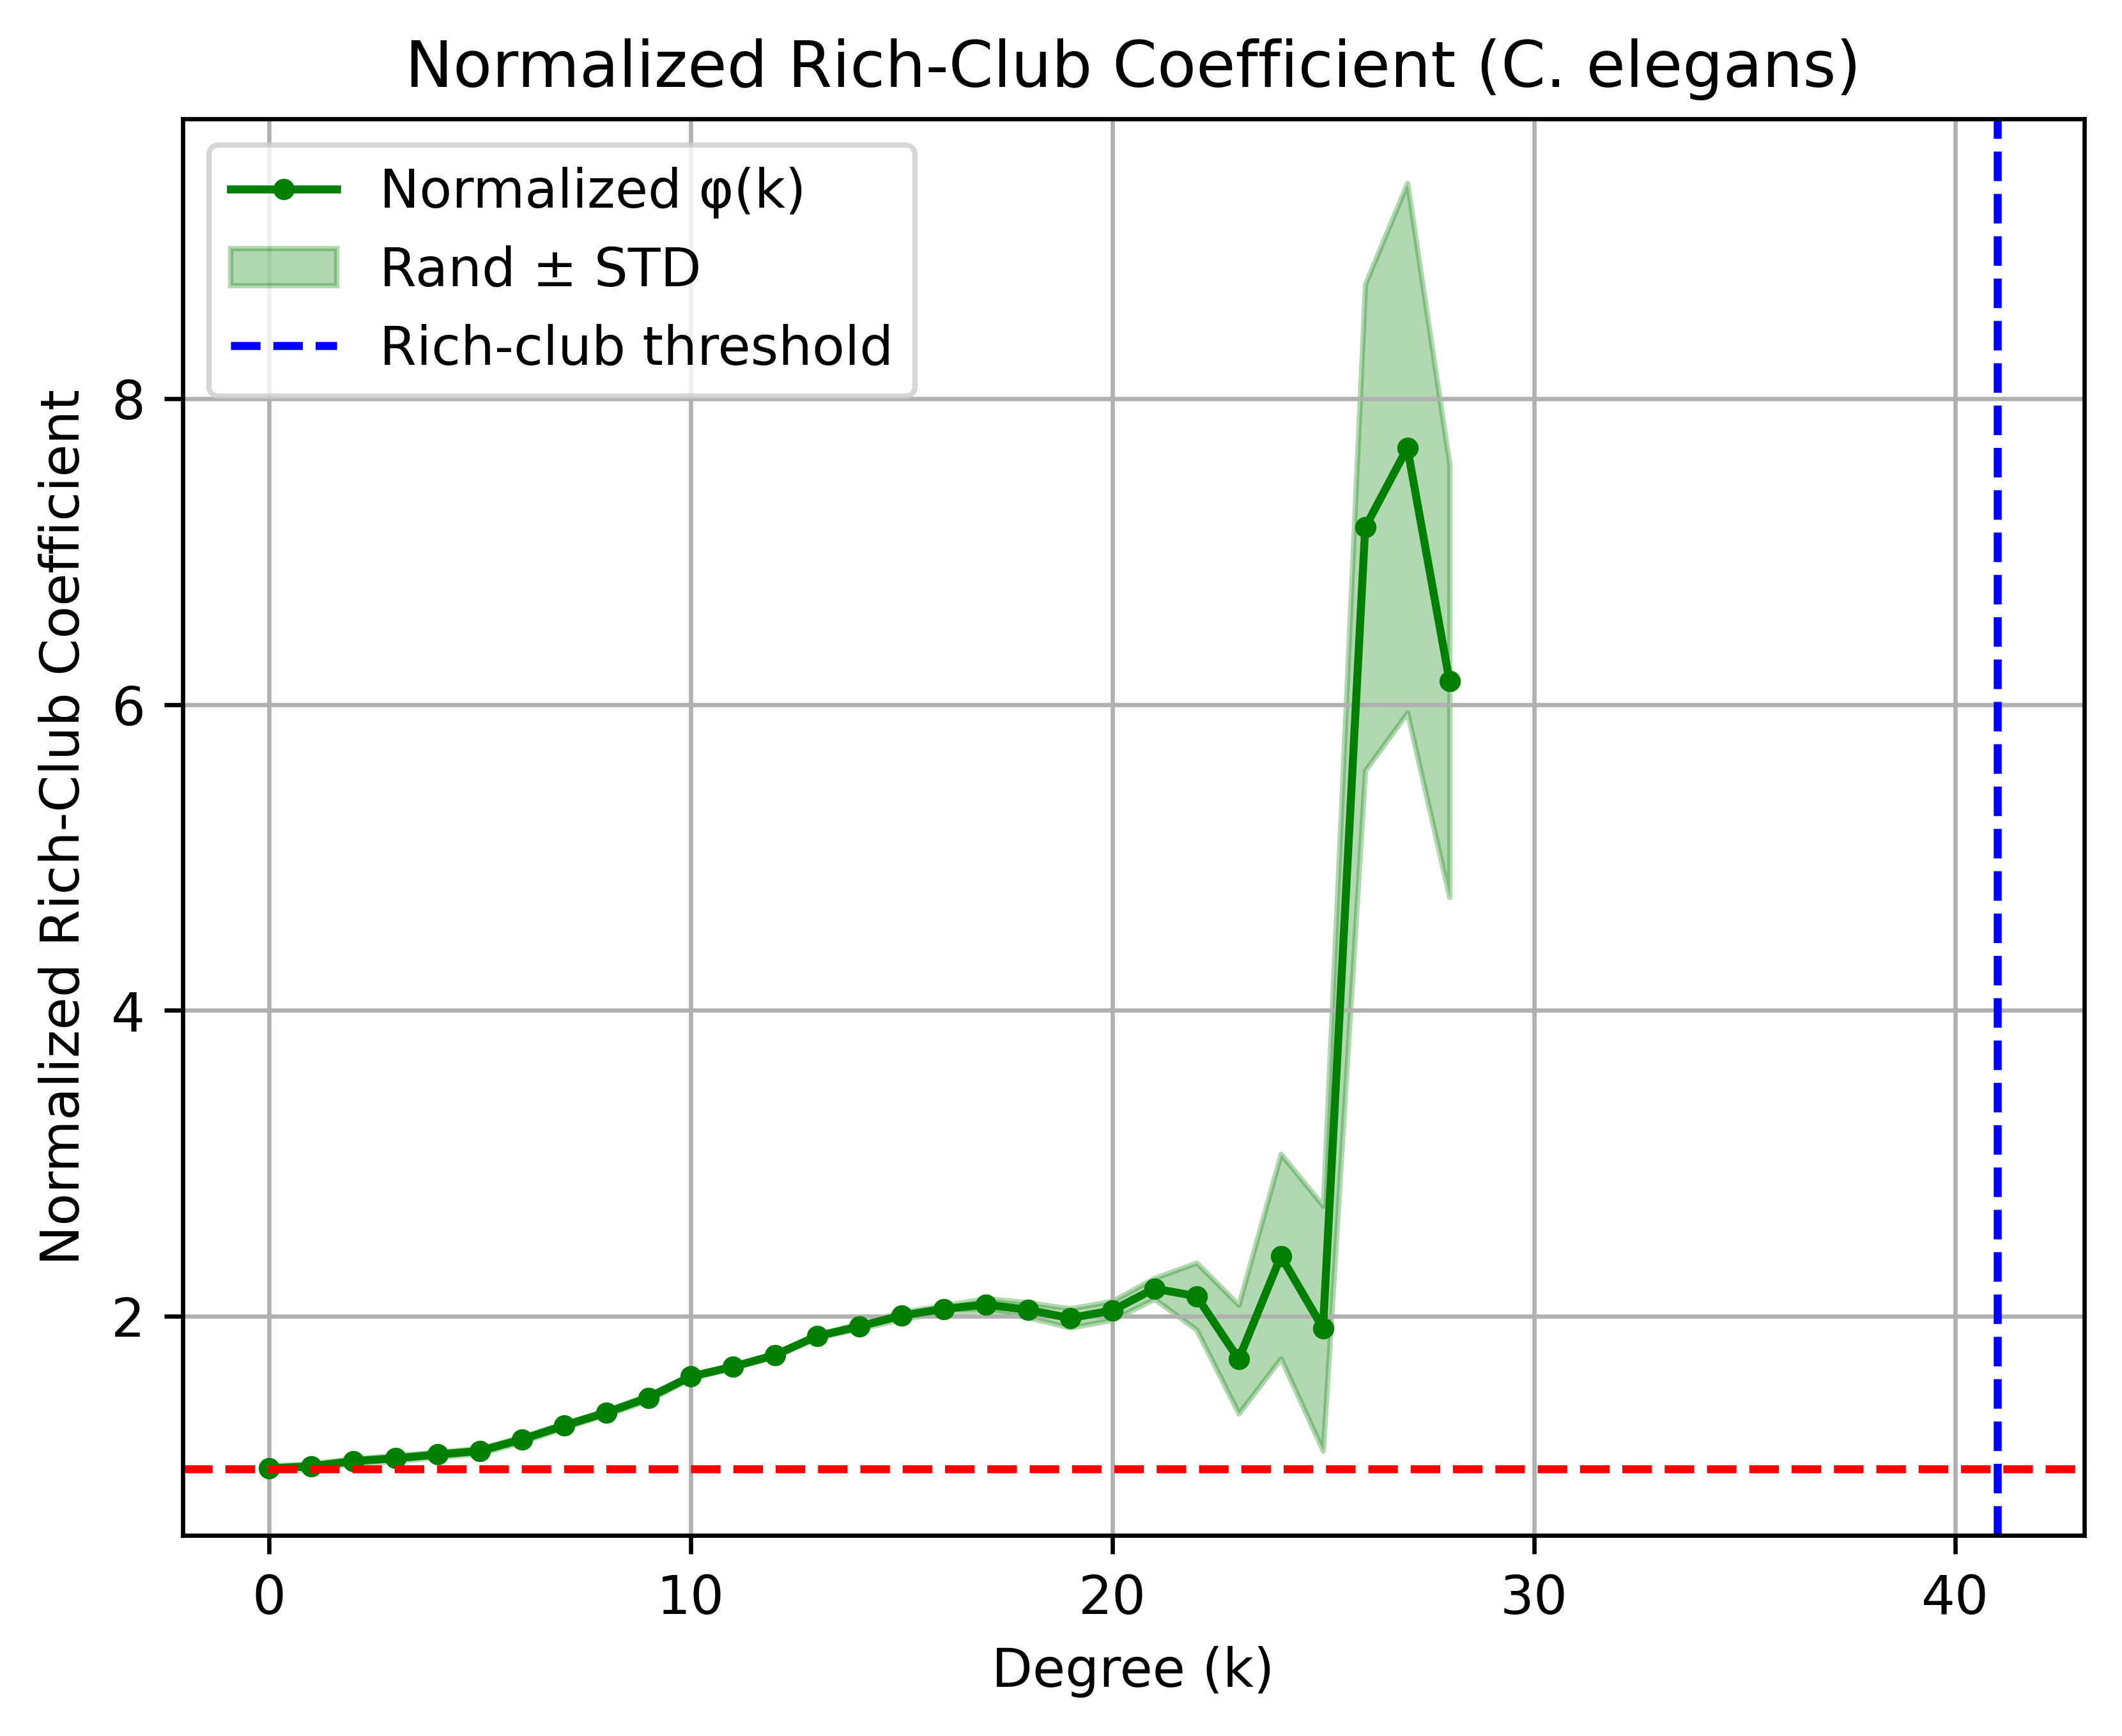

In [14]:
rc_real, rc_rand_avg, rc_rand_std, rc_norm = rich_club(G_dir, method="erdos_renyi",n_rand=10)
plot_rich_club(rc_real,rc_rand_avg,rc_rand_std,rc_norm,k_vals,k_rich)


## Let's see how these random networks diverge from the real ones: 
### We are calculating graph metrics for the real, the configuration-preserved randomized, and the Erdos-Renyi ntwrkx

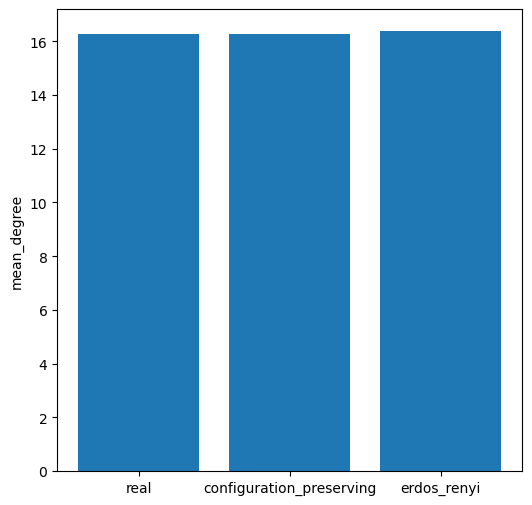

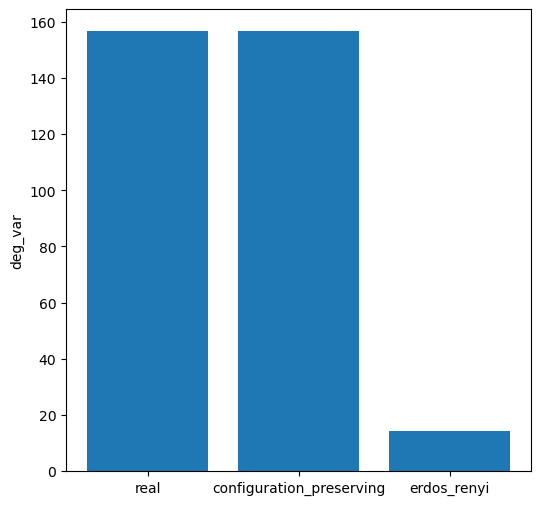

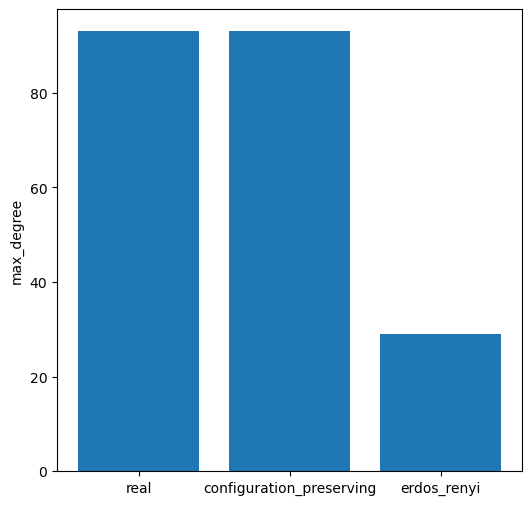

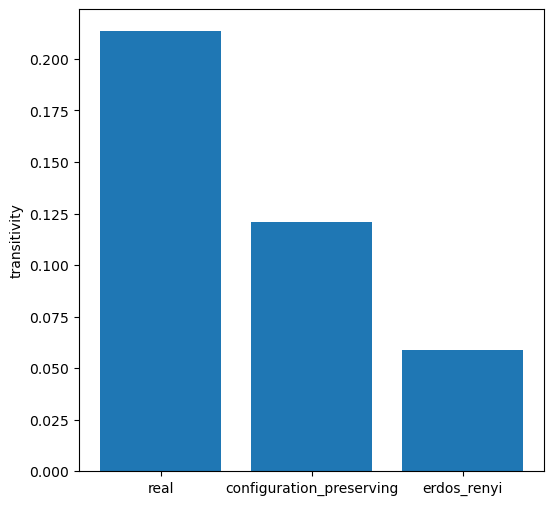

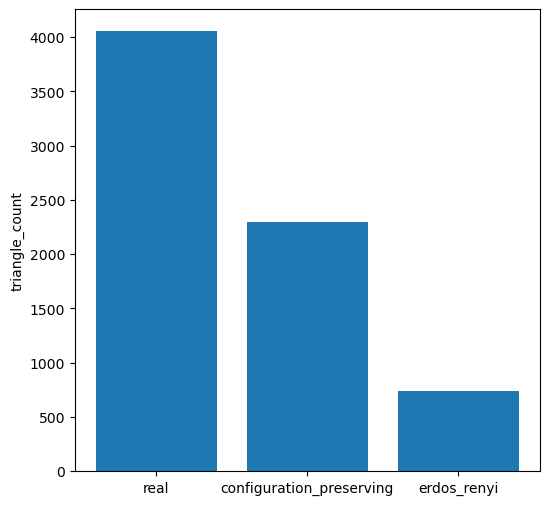

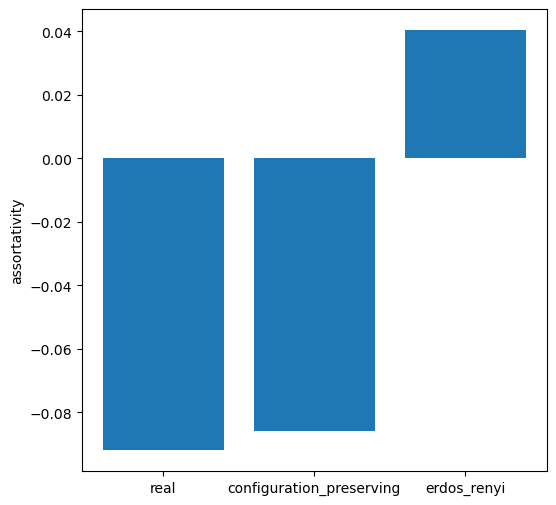

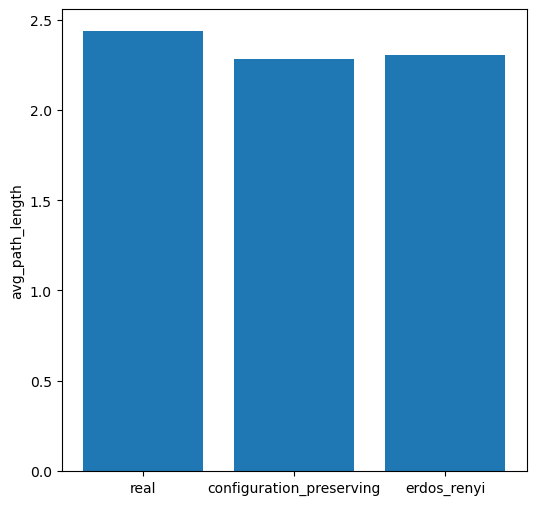

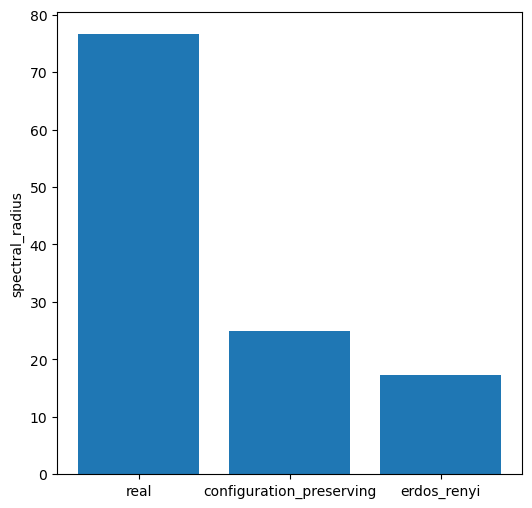

In [15]:
#Erdos-Renyi as the base of comparison ========================================

avg_degree_real = np.mean([d for n, d in G_und.degree()])
m_real = metric_set(G_und)


G_preserved = randomize_graph(G_und, method="config_preserving")
avg_degree_preserved = np.mean([d for n, d in G_preserved.degree()])
m_preserved = metric_set(G_preserved)

G_er = randomize_graph(G_und, method="erdos_renyi")
avg_degree_er = np.mean([d for n, d in G_er.degree()])
m_er = metric_set(G_er)
labels = ['real','configuration_preserving', 'erdos_renyi']

for i in m_er.keys():
    fig, ax = plt.subplots(figsize=(6,6))
    ax.set_ylabel(i)
    ax.bar(range(3),[m_real[i],m_preserved[i],m_er[i]])
    ax.set_xticks(range(3))
    ax.set_xticklabels(labels)
    plt.show()


# Let us look at the connectivity statistics of the network 
* Betweeness
* Degree
* Nodal efficiency
* Participation

In [ ]:
#BETWEENNESS 
G = G_und

degree_dict = dict(G.degree()) # puts all the degrees into a dict. 
betweenness = nx.betweenness_centrality(G, normalized=True)
print(betweenness['AIAL'])
print(betweenness['AVAL'])


## Participation coefficient

In [ ]:
communities = list(community.greedy_modularity_communities(G))
modules = {}
for i, com in enumerate(communities):
    for node in com:
        modules[node] = i
participation = participation_coefficient(G, modules)
print(participation['AIAL'])
print(participation['AVAL'])


## Nodal efficiency

In [ ]:
nodal_eff = nodal_efficiency(G)
print(nodal_eff['AIAL'])
print(nodal_eff['AVAL'])

## Determining Rich Club, Periphery, and Whole Network

In [ ]:
# ======== RICH CLUB CLASSIFICATION ==========================================
#back up richclub from the paper (for comparison)
richclub_nodes_paper = ['AVDR',
 'AVAR',
 'AVBL',
 'AVBR',
 'AVDL',
 'AVEL',
 'AVAL',
 'AVER',
 'PVCL',
 'DVA',
 'PVCR']

threshold = 44
richclub_nodes = [n for n, d in degree_dict.items() if d >= threshold]
labels = {n: ("Rich club" if n in richclub_nodes else "Periphery") for n in G.nodes()} # CONSTRUCTING LABELS 

# ======== ASSEMBLE DATAFRAME =================================================
df = pd.DataFrame({
    "neuron": list(G.nodes()),
    "degree": [degree_dict[n] for n in G.nodes()],
    "betweenness": [betweenness[n] for n in G.nodes()],
    "nodal_eff": [nodal_eff[n] for n in G.nodes()],
    "participation": [participation[n] for n in G.nodes()],
    "group": [labels[n] for n in G.nodes()]  # THIS LABELS THEM EITHER as RC or PRERIPHERY
})

# Add "Whole network" group by duplicating rows
df_whole = df.copy()
df_whole["group"] = "Whole network"
df_all = pd.concat([df, df_whole], ignore_index=True)
print(df_all)


## Plotting the coefficients for:
* Rich club
* periphery 
* whole network 

In [ ]:
# ======== PLOTS ==============================================================
metrics = ["degree", "betweenness", "nodal_eff", "participation"]
labels = ["Degree","Betweenness", "Nodal efficiency", "Participation"]

for m,l in zip(metrics,labels):
    plt.figure(figsize=(6,5))
    sns.boxplot(
        data=df_all,
        x="group", y=m,
        hue="group",
        order=["Rich club", "Periphery", "Whole network"],
        palette=["#F72585", "#7209B7", "#3A0CA3"], #["red", "blue", "gray"],
        legend=False
        )
    sns.stripplot(data=df_all, x="group", y=m, order=["Rich club","Periphery","Whole network"],
                  color="k", size=3, jitter=True, alpha=0.6)
    plt.ylabel(l)
    plt.title(l)
    plt.tight_layout()
    plt.show()